# 11 · 파운데이션 모델과 공개 AI 툴 활용
### 실습으로 배우는 신약개발 AI — 종합 (목차 ③·⑦·⑫ 심화)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/11_Foundation_Models_and_Public_Tools.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | (최종 예제) **직접 모델을 만들지 않고** 공개된 파운데이션 모델·AI 툴·공개 DB 를 조합해 실무 문제를 푸는 법 |
| **다루는 툴** | ① **ADMET-AI** (TDC 기반 ADMET 예측 툴, 104개 항목) ② **ChemBERTa · MoLFormer** 분자 파운데이션 모델 ③ **파인튜닝(전이학습)** ④ 공개 DB API (**ChEMBL · PubChem**) ⑤ **LLM(Gemini) 연구 조수** |
| **사례** | 폐암 표적 **EGFR** 저해제 — 실제 승인 약물(게피티닙·오시머티닙 등)의 ADMET 프로파일링 + 활성 예측 |
| **실행 환경** | CPU 가능(약 15분) · GPU 권장 |

> **"만들 것인가, 가져다 쓸 것인가"** — 실무에서는 공개 모델·툴로 **기준선(baseline)** 을 먼저 세우고, 필요한 곳에만 직접 모델을 만듭니다.

In [1]:
# ⚠️ 설치에 2~4분 걸립니다 (ADMET-AI 는 chemprop·lightning 등을 함께 설치)
%pip install -q rdkit koreanize-matplotlib transformers admet-ai
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, time, os
import warnings; warnings.filterwarnings("ignore")
from rdkit import Chem, DataStructs, RDLogger; RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import Draw, Descriptors, rdFingerprintGenerator
print("✅ 준비 완료")

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료


## 공개 AI 툴·모델 지형도 (2026 기준)
| 분류 | 대표 도구 | 용도 | 접근 |
|---|---|---|---|
| **분자 파운데이션 모델** | ChemBERTa, **MoLFormer-XL**(IBM), MolE | SMILES 임베딩 → 물성·활성 예측 | HuggingFace |
| **단백질 파운데이션 모델** | **ESM-2 / ESM-3**, ProtTrans, ProGen | 서열 임베딩·변이·설계 | HuggingFace |
| **구조 예측** | AlphaFold DB, ESMFold, **Boltz-2**, Chai-1 | 구조·복합체 예측 | 웹/오픈소스 |
| **ADMET 예측** | **ADMET-AI**, SwissADME, pkCSM | 약물성·독성 일괄 평가 | pip / 웹 |
| **도킹** | AutoDock Vina, GNINA, DiffDock | 결합 자세·에너지 | pip / 오픈소스 |
| **생성 설계** | REINVENT 4, MolMIM, DiffSBDD | 신규 분자 설계 | 오픈소스 |
| **합성 경로** | AiZynthFinder, ASKCOS | 역합성 경로 제안 | 오픈소스 |
| **공개 DB** | ChEMBL, PubChem, Open Targets, PDB, DepMap | 데이터 | REST API |
| **범용 LLM** | Gemini, Claude, GPT | 코딩·문헌·규제 문서 보조 | API |

## 1. 공개 DB API — ChEMBL 에서 EGFR 활성 데이터 직접 받기
**ChEMBL**(EMBL-EBI)은 240만 개 화합물·2,000만 건 생체활성을 담은 표준 DB 입니다. REST API 로 바로 받을 수 있습니다.
- 표적: **EGFR** (ChEMBL ID: `CHEMBL203`) — 비소세포폐암의 대표 표적

In [2]:
REPO = "https://raw.githubusercontent.com/StillWork/DrugAI/main/data/"
def load_data(name, **kw):
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else REPO + name, **kw)

def fetch_chembl(target="CHEMBL203", n=3000):
    url = "https://www.ebi.ac.uk/chembl/api/data/activity.json"
    params = {"target_chembl_id": target, "standard_type": "IC50", "standard_relation": "=",
              "standard_units": "nM", "assay_type": "B", "limit": 1000,
              "only": "molecule_chembl_id,canonical_smiles,pchembl_value"}
    rows = []
    for off in range(0, n, 1000):
        params["offset"] = off
        rows += requests.get(url, params=params, timeout=120).json()["activities"]
    return pd.DataFrame(rows)

try:
    t = time.time(); raw = fetch_chembl(); print(f"[ChEMBL 실시간] {len(raw)}건 수신 ({time.time()-t:.0f}초)")
    df = raw.dropna(subset=["pchembl_value", "canonical_smiles"]).copy()
    df["pchembl_value"] = df["pchembl_value"].astype(float)
    df = df.groupby(["molecule_chembl_id", "canonical_smiles"], as_index=False)["pchembl_value"].median().rename(columns={"pchembl_value": "pIC50"})
except Exception as e:
    print("ChEMBL API 응답 없음 → 스냅샷 사용:", e)
    df = load_data("chembl_egfr_ic50_snapshot.csv")

df["mol"] = df["canonical_smiles"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)
print(f"EGFR 저해제 {len(df)}개  pIC50 {df.pIC50.min():.1f} ~ {df.pIC50.max():.1f}")
df.head(3)[["molecule_chembl_id", "canonical_smiles", "pIC50"]]

[ChEMBL 실시간] 3000건 수신 (18초)


EGFR 저해제 2187개  pIC50 4.0 ~ 11.0


,molecule_chembl_id,canonical_smiles,pIC50
0,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,4.02
1,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,6.34
2,CHEMBL101683,O=C(Nc1ccc(Cl)cc1)c1ccccc1NCc1ccncc1,5.14


## 2. 공개 DB API — PubChem 에서 실제 승인 약물 가져오기
**PubChem PUG REST API**: 약물 **이름만으로** 구조(SMILES)를 조회할 수 있습니다.

,약물,설명,CID,분자량
0,gefitinib,1세대 EGFR 저해제 (이레사),123631,446.9
1,erlotinib,1세대 (타쎄바),176870,393.4
2,afatinib,2세대 비가역적,10184653,485.9
3,osimertinib,"3세대, T790M 내성 극복 (타그리소)",71496458,499.6
4,lazertinib,3세대 국산 신약 (렉라자),121269225,554.6
5,lapatinib,EGFR/HER2 이중 저해,208908,581.1


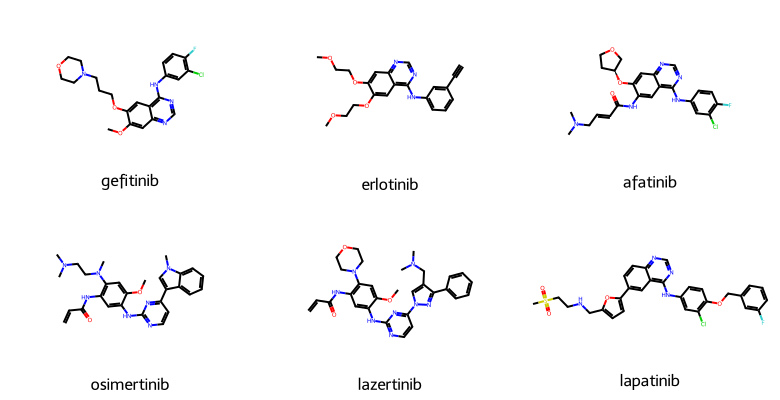

In [3]:
drug_names = ["gefitinib", "erlotinib", "afatinib", "osimertinib", "lazertinib", "lapatinib"]
drug_info = {"gefitinib": "1세대 EGFR 저해제 (이레사)", "erlotinib": "1세대 (타쎄바)", "afatinib": "2세대 비가역적",
             "osimertinib": "3세대, T790M 내성 극복 (타그리소)", "lazertinib": "3세대 국산 신약 (렉라자)", "lapatinib": "EGFR/HER2 이중 저해"}
rows = []
for name in drug_names:
    r = requests.get(f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{name}/property/SMILES,MolecularWeight/JSON", timeout=60)
    p = r.json()["PropertyTable"]["Properties"][0]
    rows.append({"약물": name, "설명": drug_info[name], "CID": p["CID"], "SMILES": p["SMILES"], "분자량": float(p["MolecularWeight"])})
drugs = pd.DataFrame(rows)
display(drugs[["약물", "설명", "CID", "분자량"]])
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in drugs.SMILES], molsPerRow=3, subImgSize=(260, 200), legends=list(drugs.약물))

## 3. ⭐ 공개 툴 ① ADMET-AI — 모델 학습 없이 ADMET 104개 항목 예측
**ADMET-AI**(Stanford, 2024)는 **TDC(Therapeutics Data Commons)** 의 41개 ADMET 데이터셋으로 학습한 Chemprop-RDKit 모델을 패키지로 제공합니다.
`pip install admet-ai` 한 줄이면 **흡수·분포·대사·배설·독성**을 일괄 예측하고, **DrugBank 승인 약물 대비 백분위**까지 알려줍니다.

In [4]:
import logging
for n in ["lightning", "lightning.pytorch", "pytorch_lightning", "chemprop"]:
    logging.getLogger(n).setLevel(logging.ERROR)
from admet_ai import ADMETModel
t = time.time(); admet = ADMETModel(); print(f"ADMET-AI 모델 로드 ({time.time()-t:.0f}초)")
pred = admet.predict(smiles=list(drugs.SMILES))
pred.index = list(drugs.약물)
print("예측 항목 수:", pred.shape[1])
key = ["molecular_weight", "logP", "QED", "HIA_Hou", "Bioavailability_Ma", "BBB_Martins", "Pgp_Broccatelli",
       "CYP3A4_Veith", "CYP2D6_Veith", "hERG", "DILI", "AMES", "Clearance_Hepatocyte_AZ", "Half_Life_Obach", "Solubility_AqSolDB"]
pred[key].round(2)

ADMET-AI 모델 로드 (0초)


SMILES to Mol:   0%|          | 0/6 [00:00<?, ?it/s]

SMILES to Mol: 100%|██████████| 6/6 [00:00<00:00, 2350.19it/s]

Computing physchem properties:   0%|          | 0/6 [00:00<?, ?it/s]

Computing physchem properties: 100%|██████████| 6/6 [00:00<00:00, 150.61it/s]

...

TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


model ensembles: 100%|██████████| 2/2 [00:00<00:00,  9.57it/s]

예측 항목 수: 104


,molecular_weight,logP,QED,HIA_Hou,Bioavailability_Ma,BBB_Martins,Pgp_Broccatelli,CYP3A4_Veith,CYP2D6_Veith,hERG,DILI,AMES,Clearance_Hepatocyte_AZ,Half_Life_Obach,Solubility_AqSolDB
gefitinib,446.91,4.28,0.52,1.00,0.89,0.82,0.81,0.80,0.36,0.96,0.89,0.60,31.360001,97.290001,-4.51
erlotinib,393.44,3.41,0.42,1.00,0.90,0.43,0.67,0.86,0.09,0.81,0.97,0.52,53.889999,84.220001,-4.56
afatinib,485.95,4.39,0.46,0.98,0.85,0.41,0.57,0.38,0.10,0.87,0.94,0.68,20.809999,102.360001,-4.79
osimertinib,499.62,4.51,0.31,0.98,0.80,0.39,0.67,0.56,0.28,0.93,0.91,0.62,27.760000,87.720001,-4.85
lazertinib,554.66,4.10,0.28,0.98,0.87,0.17,0.86,0.31,0.06,0.89,0.98,0.23,18.160000,56.930000,-4.60
lapatinib,581.07,6.14,0.18,1.00,0.83,0.57,0.95,0.96,0.78,0.98,0.97,0.81,20.950001,126.080002,-5.65


| 항목 | 의미 | 좋은 방향 |
|---|---|---|
| HIA_Hou | 사람 장관 흡수 | 높을수록 좋음 |
| Bioavailability_Ma | 경구 생체이용률 | 높을수록 좋음 |
| BBB_Martins | 혈액뇌장벽 투과 | 뇌 전이 치료는 높아야, 중추 부작용 회피는 낮아야 |
| Pgp_Broccatelli | P-당단백질 배출 기질 | 낮을수록 흡수·뇌 전달 유리 |
| CYP3A4/2D6_Veith | 대사효소 저해 | 낮을수록 **약물 상호작용** 위험 적음 |
| **hERG** | 심장 칼륨채널 차단 → **부정맥 위험** | 낮을수록 안전 |
| **DILI** | 약물 유발 간손상 | 낮을수록 안전 |
| AMES | 변이원성 | 낮을수록 안전 |

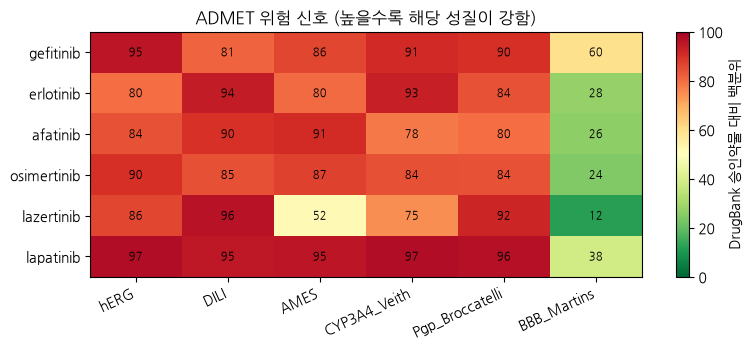

※ 백분위가 높다고 모두 나쁜 것은 아닙니다. 예: 뇌 전이 치료제는 BBB 투과가 높아야 유리합니다.


In [5]:
# 승인 약물 대비 백분위로 '위험 신호' 한눈에 보기
risk = ["hERG", "DILI", "AMES", "CYP3A4_Veith", "Pgp_Broccatelli", "BBB_Martins"]
pct = pred[[c + "_drugbank_approved_percentile" for c in risk]]
pct.columns = risk
plt.figure(figsize=(8, 3.6))
plt.imshow(pct.values, cmap="RdYlGn_r", vmin=0, vmax=100, aspect="auto")
plt.xticks(range(len(risk)), risk, rotation=25, ha="right"); plt.yticks(range(len(pct)), pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        plt.text(j, i, f"{pct.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(label="DrugBank 승인약물 대비 백분위"); plt.title("ADMET 위험 신호 (높을수록 해당 성질이 강함)"); plt.tight_layout(); plt.show()
print("※ 백분위가 높다고 모두 나쁜 것은 아닙니다. 예: 뇌 전이 치료제는 BBB 투과가 높아야 유리합니다.")

In [6]:
# 생성형 AI 가 만든 분자(예제 10)도 ADMET-AI 로 바로 평가할 수 있습니다
new_molecules = ["O=C(NCCC(=O)N1CCCc2occc2C1)c1ccc(F)cc1", "Cc1cnc(C(=O)N(C)c2ccc3c(C)cc(=O)oc3c2)cc1C"]
gen_pred = admet.predict(smiles=new_molecules)
gen_pred[["QED", "HIA_Hou", "hERG", "DILI", "AMES", "Solubility_AqSolDB", "Clearance_Hepatocyte_AZ"]].round(2)

SMILES to Mol:   0%|          | 0/2 [00:00<?, ?it/s]

SMILES to Mol: 100%|██████████| 2/2 [00:00<00:00, 5664.15it/s]

Computing physchem properties:   0%|          | 0/2 [00:00<?, ?it/s]

Computing physchem properties: 100%|██████████| 2/2 [00:00<00:00, 200.82it/s]

model ensembles:   0%|          | 0/2 [00:00<?, ?it/s]

...

TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


model ensembles: 100%|██████████| 2/2 [00:00<00:00, 13.16it/s]

model ensembles: 100%|██████████| 2/2 [00:00<00:00, 13.14it/s]

,QED,HIA_Hou,hERG,DILI,AMES,Solubility_AqSolDB,Clearance_Hepatocyte_AZ
O=C(NCCC(=O)N1CCCc2occc2C1)c1ccc(F)cc1,0.94,1.0,0.53,0.60,0.26,-2.34,57.080002
Cc1cnc(C(=O)N(C)c2ccc3c(C)cc(=O)oc3c2)cc1C,0.68,1.0,0.24,0.97,0.07,-4.57,95.019997


## 4. ⭐ 공개 툴 ② 분자 파운데이션 모델 — ChemBERTa vs MoLFormer
사전학습 모델에서 **임베딩(분자 벡터)** 을 꺼내 쓰면, 적은 데이터로도 좋은 예측이 가능합니다.

| 모델 | 기관 | 사전학습 데이터 | 임베딩 차원 |
|---|---|---|---|
| **ChemBERTa-77M-MTR** | DeepChem | PubChem 7,700만 분자 | 384 |
| **MoLFormer-XL-both-10pct** | IBM | ZINC+PubChem 11억 분자의 10% | 768 |

In [7]:
import torch
from transformers import AutoTokenizer, AutoModel
import transformers; transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
device = "cuda" if torch.cuda.is_available() else "cpu"
smiles = [Chem.MolToSmiles(m) for m in df.mol]

def get_embeddings(model_name, smiles, batch=64, **kw):
    tok = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
    mod = AutoModel.from_pretrained(model_name, trust_remote_code=True, **kw).to(device).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(smiles), batch):
            e = tok(smiles[i:i + batch], padding=True, truncation=True, max_length=202, return_tensors="pt").to(device)
            h = mod(**e).last_hidden_state
            m = e["attention_mask"].unsqueeze(-1)
            out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())      # 토큰 평균 = 분자 임베딩
    return np.vstack(out)

t = time.time(); E_chem = get_embeddings("DeepChem/ChemBERTa-77M-MTR", smiles); print("ChemBERTa", E_chem.shape, f"{time.time()-t:.0f}초")
t = time.time(); E_mol = get_embeddings("ibm/MoLFormer-XL-both-10pct", smiles, deterministic_eval=True); print("MoLFormer", E_mol.shape, f"{time.time()-t:.0f}초")

morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
FP = np.array([morgan.GetCountFingerprintAsNumPy(m) for m in df.mol], dtype=np.float32)
y = df.pIC50.values

ChemBERTa (2187, 384) 5초


MoLFormer (2187, 768) 38초


### 임베딩 공간 시각화 — 파운데이션 모델은 분자를 어떻게 '이해'하는가

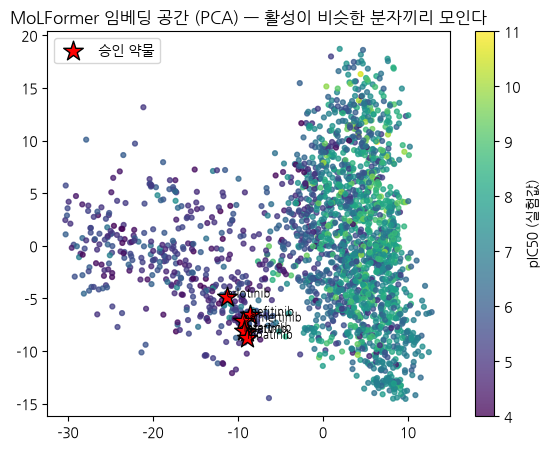

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
P = PCA(2).fit_transform(StandardScaler().fit_transform(E_mol))
plt.figure(figsize=(6.5, 5))
s = plt.scatter(P[:, 0], P[:, 1], c=y, cmap="viridis", s=12, alpha=0.75)
plt.colorbar(s, label="pIC50 (실험값)")
# 승인 약물의 위치도 함께 표시
E_drug = get_embeddings("ibm/MoLFormer-XL-both-10pct", list(drugs.SMILES), deterministic_eval=True)
Pd = PCA(2).fit(StandardScaler().fit_transform(E_mol)).transform(StandardScaler().fit(E_mol).transform(E_drug))
plt.scatter(Pd[:, 0], Pd[:, 1], marker="*", s=220, c="red", edgecolors="k", label="승인 약물")
for (x_, y_), n in zip(Pd, drugs.약물): plt.annotate(n, (x_, y_), fontsize=8)
plt.legend(); plt.title("MoLFormer 임베딩 공간 (PCA) — 활성이 비슷한 분자끼리 모인다"); plt.show()

### ⭐ 데이터가 적을 때 진가 — 소량 데이터(few-shot) 성능 비교
학습 데이터 수를 32개부터 늘려가며 **직접 만든 특성(Morgan 지문)** 과 **파운데이션 모델 임베딩**을 비교합니다.
평가는 **스캐폴드 분할**(예제 06)로 — 처음 보는 골격에 대한 현실적 성능.

학습 1656개 / 평가 531개 (서로 다른 스캐폴드)


방법,ChemBERTa + SVR,MoLFormer + SVR,Morgan 지문 + RF
학습 데이터 수,,,
32,0.217,0.253,0.336
64,0.306,0.318,0.409
128,0.327,0.390,0.467
256,0.402,0.442,0.530
512,0.465,0.509,0.561
1024,0.523,0.538,0.619
1656,0.564,0.570,0.642


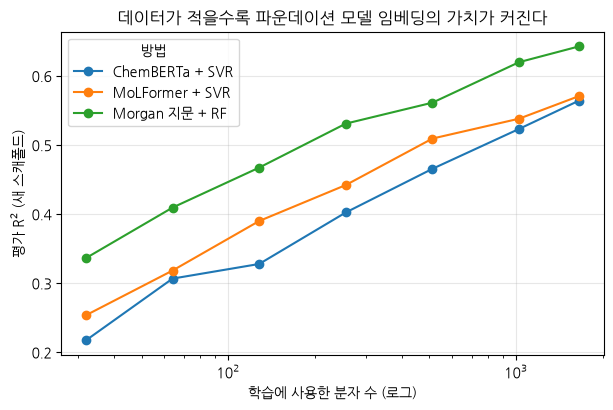

In [9]:
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score

groups = pd.factorize(pd.Series([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in df.mol]))[0]
tr, te = next(GroupShuffleSplit(1, test_size=0.25, random_state=0).split(FP, y, groups))
print(f"학습 {len(tr)}개 / 평가 {len(te)}개 (서로 다른 스캐폴드)")

setups = {"Morgan 지문 + RF": (FP, lambda: RandomForestRegressor(300, n_jobs=-1, random_state=0)),
          "ChemBERTa + SVR": (E_chem, lambda: make_pipeline(StandardScaler(), SVR(C=3))),
          "MoLFormer + SVR": (E_mol, lambda: make_pipeline(StandardScaler(), SVR(C=3)))}
rows = []
for n in [32, 64, 128, 256, 512, 1024, len(tr)]:
    for rep in range(3):
        sub = np.random.RandomState(rep).choice(tr, min(n, len(tr)), replace=False)
        for name, (X, mk) in setups.items():
            m = mk().fit(X[sub], y[sub])
            rows.append({"학습 데이터 수": n, "방법": name, "R2": r2_score(y[te], m.predict(X[te]))})
curve = pd.DataFrame(rows).groupby(["학습 데이터 수", "방법"]).R2.mean().unstack()
display(curve.round(3))
curve.plot(marker="o", figsize=(7, 4.2)); plt.xscale("log")
plt.xlabel("학습에 사용한 분자 수 (로그)"); plt.ylabel("평가 R$^2$ (새 스캐폴드)")
plt.title("데이터가 적을수록 파운데이션 모델 임베딩의 가치가 커진다"); plt.grid(alpha=0.3); plt.show()

> **해석**: 데이터가 수천 개 있으면 잘 만든 Morgan 지문 + 트리 모델이 여전히 강력합니다.
> 파운데이션 모델은 **데이터가 수십~수백 개로 적을 때**, 그리고 **파인튜닝할 때** 더 유리해집니다.
> 실무에서는 **둘 다 시도해서 교차검증으로 고르는 것**이 정답입니다.

## 5. ⭐ 파인튜닝(Fine-tuning) — 파운데이션 모델을 내 데이터에 맞게 재학습
임베딩만 꺼내 쓰는 대신, 모델 **전체 가중치를 소폭 갱신**하면 성능이 더 오릅니다.

In [10]:
import torch.nn as nn
name = "DeepChem/ChemBERTa-77M-MTR"
tok = AutoTokenizer.from_pretrained(name)

class ChemBERTaRegressor(nn.Module):
    # 사전학습 ChemBERTa 본체 + 회귀 헤드
    def __init__(self):
        super().__init__()
        self.bert = AutoModel.from_pretrained(name)
        self.head = nn.Linear(self.bert.config.hidden_size, 1)
    def forward(self, **enc):
        h = self.bert(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1)
        return self.head((h * m).sum(1) / m.sum(1)).squeeze(-1)

mu, sd = y[tr].mean(), y[tr].std()                      # 목표값 표준화 (학습 안정화)
torch.manual_seed(0)
model = ChemBERTaRegressor().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
t = time.time()
best_r2 = -9
for epoch in range(8):
    model.train()
    for i in range(0, len(tr), 32):
        b = np.random.permutation(tr)[i:i + 32] if i == 0 else tr[i:i + 32]
        enc = tok([smiles[j] for j in b], padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
        loss = nn.functional.mse_loss(model(**enc), torch.tensor((y[b] - mu) / sd, dtype=torch.float32, device=device))
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval(); P = []
    with torch.no_grad():
        for i in range(0, len(te), 128):
            enc = tok([smiles[j] for j in te[i:i + 128]], padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
            P.append(model(**enc).cpu().numpy())
    r2 = r2_score(y[te], np.concatenate(P) * sd + mu); best_r2 = max(best_r2, r2)
    print(f"  에폭 {epoch+1}: 평가 R² = {r2:.3f}  ({time.time()-t:.0f}초)")
emb_r2 = curve.loc[len(tr), "ChemBERTa + SVR"]
print(f"\n같은 ChemBERTa 로 비교 →  임베딩 + SVR: R² {emb_r2:.3f}   |   파인튜닝(최고 에폭): R² {best_r2:.3f}")
print("※ 파인튜닝은 에폭·학습률에 민감하고 실행마다 흔들립니다. 수천 개 규모 데이터에서는 임베딩 + 고전 모델이 더 좋은 경우도 흔합니다.")

  에폭 1: 평가 R² = 0.397  (14초)


  에폭 2: 평가 R² = 0.391  (25초)


  에폭 3: 평가 R² = 0.429  (36초)


  에폭 4: 평가 R² = 0.430  (47초)


  에폭 5: 평가 R² = 0.458  (57초)


  에폭 6: 평가 R² = 0.482  (75초)


  에폭 7: 평가 R² = 0.506  (86초)


  에폭 8: 평가 R² = 0.487  (97초)

같은 ChemBERTa 로 비교 →  임베딩 + SVR: R² 0.564   |   파인튜닝(최고 에폭): R² 0.506
※ 파인튜닝은 에폭·학습률에 민감하고 실행마다 흔들립니다. 수천 개 규모 데이터에서는 임베딩 + 고전 모델이 더 좋은 경우도 흔합니다.


> **언제 무엇을?**
> | 상황 | 전략 |
> |---|---|
> | 데이터 < 100 | 임베딩 + 단순 모델 (SVR/릿지), 또는 유사도 기반 |
> | 데이터 100~5,000 | 임베딩 + RF/SVR **와** 파인튜닝 둘 다 시도 |
> | 데이터 > 10,000 | 파인튜닝, 또는 직접 모델 학습(GNN) |
> | 계산 자원 부족 | 임베딩 추출(한 번) + 가벼운 모델 |

## 6. 승인 약물 활성 예측 — 만든 모델의 '현실 점검'
학습 데이터에 포함되지 않은(또는 포함됐을 수 있는) 실제 EGFR 저해제의 활성을 예측해 봅니다.

In [11]:
best = make_pipeline(StandardScaler(), SVR(C=3)).fit(E_mol[tr], y[tr])
E_drug_full = get_embeddings("ibm/MoLFormer-XL-both-10pct", list(drugs.SMILES), deterministic_eval=True)
drugs["예측 pIC50"] = best.predict(E_drug_full).round(2)
# 학습 데이터에 같은 분자가 있는지 확인 (데이터 누수 점검)
train_canon = set(smiles[i] for i in tr)
drugs["학습셋 포함?"] = [Chem.MolToSmiles(Chem.MolFromSmiles(s)) in train_canon for s in drugs.SMILES]
drugs[["약물", "설명", "예측 pIC50", "학습셋 포함?"]]

,약물,설명,예측 pIC50,학습셋 포함?
0,gefitinib,1세대 EGFR 저해제 (이레사),5.93,False
1,erlotinib,1세대 (타쎄바),5.89,True
2,afatinib,2세대 비가역적,5.80,True
3,osimertinib,"3세대, T790M 내성 극복 (타그리소)",6.32,False
4,lazertinib,3세대 국산 신약 (렉라자),6.00,False
5,lapatinib,EGFR/HER2 이중 저해,5.94,True


> **결과를 그대로 받아들이지 마세요 — 두 가지를 반드시 확인합니다.**
> 1. **데이터 누수**: `학습셋 포함? = True` 인 약물의 예측값은 성능 근거가 될 수 없습니다 (모델이 이미 본 분자).
> 2. **과소예측(평균 회귀)**: 실제 EGFR 저해제는 대개 pIC50 8~9 이상이지만, 모델 예측은 그보다 낮게 나오기 쉽습니다.
>    회귀 모델은 극단값을 평균 쪽으로 당기는 경향이 있고, 학습 데이터에는 활성이 약한 분자가 훨씬 많기 때문입니다.
>
> → 그래서 실무에서는 **절대값보다 순위(ranking)** 를 봅니다. "이 분자가 pIC50 8.5다"가 아니라
> **"후보 1,000개 중 상위 5%에 든다"** 로 해석하고, 적용 범위(예제 03)와 함께 보고합니다.

In [12]:
# 순위로 보기: 전체 라이브러리에서 각 승인 약물이 상위 몇 %로 예측되는가
all_pred = best.predict(E_mol)
for _, row in drugs.iterrows():
    pct = (all_pred < best.predict(get_embeddings("ibm/MoLFormer-XL-both-10pct", [row.SMILES], deterministic_eval=True))[0]).mean()
    print(f"{row.약물:12s} 예측 pIC50 {row['예측 pIC50']:.2f}  →  전체 {len(all_pred)}개 중 상위 {100*(1-pct):.1f}%")

gefitinib    예측 pIC50 5.93  →  전체 2187개 중 상위 72.9%


erlotinib    예측 pIC50 5.89  →  전체 2187개 중 상위 74.3%


afatinib     예측 pIC50 5.80  →  전체 2187개 중 상위 76.5%


osimertinib  예측 pIC50 6.32  →  전체 2187개 중 상위 62.6%


lazertinib   예측 pIC50 6.00  →  전체 2187개 중 상위 71.4%


lapatinib    예측 pIC50 5.94  →  전체 2187개 중 상위 72.9%


## 7. LLM 을 연구 조수로 — Colab 내장 Gemini
Colab 에는 **API 키 없이** 쓸 수 있는 Gemini 가 내장되어 있습니다 (`google.colab.ai`).
문헌 요약, 코드 생성, 결과 해석, 규제 문서 초안 등에 활용할 수 있습니다.

In [13]:
def ask_llm(prompt):
    # Colab 내장 Gemini → 실패 시 API 키(Colab 보안 비밀) 사용 → 둘 다 없으면 안내
    try:
        from google.colab import ai
        return ai.generate_text(prompt)
    except Exception:
        pass
    try:
        from google.colab import userdata
        import google.generativeai as genai
        genai.configure(api_key=userdata.get("GOOGLE_API_KEY"))
        return genai.GenerativeModel("gemini-2.5-flash").generate_content(prompt).text
    except Exception as e:
        return ("[LLM 사용 불가] Colab 에서 실행하거나, AI Studio 에서 API 키를 발급받아 "
                "Colab 보안 비밀(🔑)에 GOOGLE_API_KEY 로 저장하세요.\n사유: " + str(e)[:200])

summary = f'''
EGFR 저해제 {len(df)}개의 pIC50 데이터로 모델을 만들었습니다.
- Morgan 지문 + 랜덤포레스트: R2 = {curve.loc[len(tr), 'Morgan 지문 + RF']:.3f}
- MoLFormer 임베딩 + SVR: R2 = {curve.loc[len(tr), 'MoLFormer + SVR']:.3f}
- 평가는 스캐폴드 분할(새로운 골격)로 수행했습니다.
'''
print(ask_llm(f"다음은 신약개발 AI 모델 결과입니다. 제약회사 연구팀에게 보고할 3줄 요약과, "
              f"성능을 더 높이기 위한 구체적 제안 3가지를 한국어로 써주세요.\n{summary}"))

[LLM 사용 불가] Colab 에서 실행하거나, AI Studio 에서 API 키를 발급받아 Colab 보안 비밀(🔑)에 GOOGLE_API_KEY 로 저장하세요.
사유: No module named 'google'


In [14]:
# LLM 에게 분자 구조 해석을 요청하는 예 (결과는 반드시 전문가가 검증해야 합니다)
q = f'''다음은 폐암 표적 EGFR 저해제들의 SMILES 입니다.
게피티닙: {drugs.loc[drugs.약물=='gefitinib','SMILES'].iloc[0]}
오시머티닙: {drugs.loc[drugs.약물=='osimertinib','SMILES'].iloc[0]}
두 약물의 구조적 차이와, 3세대 저해제가 T790M 내성 변이를 극복하는 화학적 원리를 제약 연구원에게 설명하듯 한국어로 간단히 설명해주세요.'''
print(ask_llm(q))

[LLM 사용 불가] Colab 에서 실행하거나, AI Studio 에서 API 키를 발급받아 Colab 보안 비밀(🔑)에 GOOGLE_API_KEY 로 저장하세요.
사유: No module named 'google'


> ⚠️ **LLM 사용 시 주의**
> - LLM 은 **그럴듯하지만 틀린 정보(환각)** 를 만들 수 있습니다. 숫자·기전·문헌은 반드시 원본으로 검증하세요.
> - **미공개 연구 데이터·환자 정보**를 외부 LLM 에 입력하지 마세요 (사내 규정·개인정보 보호).
> - 규제 문서에 AI 결과를 쓸 때는 **사용 사실과 검증 절차를 기록** 해야 합니다 (GMP-AI 과정의 GAIP 참조).

## 🧪 LLM 코딩 과제
```
ADMET-AI 의 admet.predict() 로 ChEMBL EGFR 데이터 상위 활성 분자 50개의 ADMET 을 예측하고,
hERG 위험과 pIC50 의 관계를 산점도로 그려줘. hERG > 0.5 인 분자의 비율도 계산해줘.
```

In [15]:
# ✏️ LLM 코드 붙여넣기

## ✅ 정리 — "만들기 전에 가져다 쓰기"
| 필요 | 공개 툴 | 한 줄 |
|---|---|---|
| ADMET·독성 평가 | **ADMET-AI** | `ADMETModel().predict(smiles=[...])` |
| 분자 임베딩 | **ChemBERTa / MoLFormer** | `AutoModel.from_pretrained(...)` |
| 단백질 구조 | **AlphaFold DB / ESMFold** | REST API 한 번 |
| 도킹 | **AutoDock Vina** | `pip install vina` |
| 활성 데이터 | **ChEMBL / PubChem** | REST API |
| 타겟 근거 | **Open Targets** | GraphQL API |
| 코딩·해석 보조 | **Gemini / Claude** | `google.colab.ai` |

**실무 순서**: 공개 DB 로 데이터 확보 → 공개 모델로 기준선 → 부족한 부분만 직접 모델링 → 교차검증·적용범위로 검증 → 전문가·실험 확인

### 🎓 전체 과정 요약 — 신약개발 AI 파이프라인
```
예제 09 타겟 발굴 → 예제 08 표적 구조 → 예제 10 분자 설계 → 예제 07 스크리닝·도킹
      → 예제 03·04·06 물성·독성·활성 예측 → 예제 11 ADMET 평가 → 실험 검증
```
각 단계의 공통 토대는 **예제 01(분자 표현형) · 02(성능 평가) · 05(모델 선택)** 입니다.